1: Carga de Datos y Configuración Inicial

In [1]:
from pathlib import Path
import hashlib

import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

# Localizar la raíz del repositorio.
nombre_csv = "WA_Fn-UseC_-HR-Employee-Attrition.csv"
carpeta_actual = Path.cwd().resolve()

raiz = next(
    (
        carpeta
        for carpeta in [carpeta_actual, *carpeta_actual.parents]
        if (carpeta / "datos" / nombre_csv).is_file()
    ),
    None
)

if raiz is None:
    raise FileNotFoundError(
        "No se encontró el dataset en la carpeta datos del repositorio."
    )

ruta_datos = raiz / "datos" / nombre_csv
carpeta_resultados = raiz / "S2" / "resultados"
carpeta_figuras = raiz / "S2" / "figuras"

carpeta_resultados.mkdir(parents=True, exist_ok=True)
carpeta_figuras.mkdir(parents=True, exist_ok=True)

# Conservar el original y trabajar sobre una copia.
original = pd.read_csv(ruta_datos)
df = original.copy(deep=True)
huella_csv = hashlib.sha256(ruta_datos.read_bytes()).hexdigest()

SEMILLA = 42
N_PERMUTACIONES = 10_000
ALFA = 0.05

# Generador exclusivo de este bloque.
rng_permutacion = np.random.default_rng(
    np.random.SeedSequence([SEMILLA, 5])
)

sns.set_theme(style="whitegrid")

# Leer los resultados de S1 para compararlos con la permutación.
referencias_pruebas = pd.read_csv(
    carpeta_resultados / "S1_referencia_pruebas.csv",
    encoding="utf-8-sig",
    float_precision="round_trip"
)

print("Raíz del repositorio:", raiz)
print("Dimensiones del dataset:", df.shape)
print("Valores faltantes:", int(df.isna().sum().sum()))
print("Filas duplicadas:", int(df.duplicated().sum()))
print("Permutaciones previstas:", N_PERMUTACIONES)
display(referencias_pruebas)

Raíz del repositorio: C:\Users\hernan.saavedra\Documents\2026\Magister\Estadisticas\estadisticaComputacional
Dimensiones del dataset: (1470, 35)
Valores faltantes: 0
Filas duplicadas: 0
Permutaciones previstas: 10000


,prueba,estadistico,gl,valor_p,v_cramer,esperada_minima,diferencia_medias,ic95_inferior,ic95_superior
0,Chi-cuadrado sin correccion,89.043879,1.000000,3.861518e-21,0.246118,67.069388,NaN,NaN,NaN
1,Welch bilateral permanece menos sale,7.482622,412.740748,4.433589e-13,NaN,NaN,2045.646832,1508.243516,2583.050149


2: Test de Permutación para la Comparación de Ingresos según Salida (Attrition)

In [2]:
# Grupos en el mismo orden utilizado en S1.
ingresos_no = df.loc[
    df["Attrition"] == "No", "MonthlyIncome"
].to_numpy(dtype=float)

ingresos_si = df.loc[
    df["Attrition"] == "Yes", "MonthlyIncome"
].to_numpy(dtype=float)


def welch_t_stat(x, y):
    """Diferencia de medias dividida por su error estándar de Welch."""
    error = np.sqrt(
        x.var(ddof=1) / len(x) + y.var(ddof=1) / len(y)
    )
    if error == 0:
        raise ValueError("El error estándar es cero.")
    return (x.mean() - y.mean()) / error


# Resultado paramétrico y referencia original de S1.
welch_original = stats.ttest_ind(
    ingresos_no, ingresos_si, equal_var=False
)

referencia_welch = referencias_pruebas.loc[
    referencias_pruebas["diferencia_medias"].notna()
].iloc[0]

t_obs = welch_t_stat(ingresos_no, ingresos_si)

assert np.isclose(t_obs, referencia_welch["estadistico"])
assert np.isclose(
    welch_original.pvalue,
    referencia_welch["valor_p"],
    rtol=1e-8,
    atol=0
)

# Reiniciar el generador permite reproducir esta celda por separado.
rng_permutacion = np.random.default_rng(
    np.random.SeedSequence([SEMILLA, 5])
)

combinados = np.concatenate([ingresos_no, ingresos_si])
n_no = len(ingresos_no)
t_permutados = np.empty(N_PERMUTACIONES)

for i in range(N_PERMUTACIONES):
    permutados = rng_permutacion.permutation(combinados)
    t_permutados[i] = welch_t_stat(
        permutados[:n_no], permutados[n_no:]
    )

# Contraste bilateral con corrección +1.
extremos = int(
    np.count_nonzero(np.abs(t_permutados) >= abs(t_obs))
)
p_permutacion = (extremos + 1) / (N_PERMUTACIONES + 1)

print("Orden de comparación: permanece − sale")
print(f"Tamaños de grupo: {len(ingresos_no)} y {len(ingresos_si)}")
print(f"t observado: {t_obs:.4f}")
print(f"Valor p de Welch en S1: {referencia_welch['valor_p']:.6g}")
print(f"Permutaciones: {N_PERMUTACIONES}")
print(f"Permutaciones tan extremas o más: {extremos}")
print(f"Valor p de permutación (+1): {p_permutacion:.8f}")
print(
    "Decisión con α = 0,05:",
    "Rechazar H0" if p_permutacion < ALFA else "No rechazar H0"
)

Orden de comparación: permanece − sale
Tamaños de grupo: 1233 y 237
t observado: 7.4826
Valor p de Welch en S1: 4.43359e-13
Permutaciones: 10000
Permutaciones tan extremas o más: 0
Valor p de permutación (+1): 0.00009999
Decisión con α = 0,05: Rechazar H0


### Hipótesis, método e interpretación

Se compara el ingreso mensual medio entre quienes permanecen y quienes
salen, manteniendo el orden **permanece − sale**.

- **H₀:** las medias de ingreso mensual de ambos grupos son iguales.
- **H₁:** las medias de ingreso mensual son diferentes.
- **Nivel de significancia:** α = 0,05, fijado antes del contraste como
  umbral convencional para esta evaluación.

Se utiliza el estadístico t de Welch, que divide la diferencia de medias
por un error estándar que permite varianzas distintas. En cada una de las
10.000 permutaciones se reasignan los ingresos entre los grupos,
conservando sus tamaños, y se recalcula todo el estadístico.

El estadístico observado es t = 7,4826. Ninguna permutación produjo un valor
absoluto tan extremo como el observado. Aplicando la corrección
(b + 1)/(B + 1), el valor p de permutación es 0,00009999.

Este valor corresponde al mínimo que puede obtener este procedimiento
con 10.000 permutaciones; no significa que el valor p subyacente sea
exactamente 0,0001. La simulación no permite resolver valores tan pequeños
como el p de Welch de S1 (4,43359 × 10⁻¹³).

Ambos métodos rechazan H₀ con α = 0,05. La concordancia respalda la
conclusión de una diferencia de ingresos medios, favorable al grupo que
permanece. Su magnitud observada en S1 es de 2.045,65 unidades monetarias
del dataset, con IC del 95 % de [1.508,24; 2.583,05].

### Supuestos y alcance

La permutación de etiquetas es exacta bajo intercambiabilidad, que requiere
distribuciones iguales bajo la hipótesis nula y observaciones independientes.
La igualdad de medias por sí sola no garantiza esa condición.

La studentización con Welch permite una justificación asintótica para
contrastar medias con varianzas diferentes, bajo condiciones de regularidad;
no convierte la prueba en exacta para muestras finitas en ese escenario.
Por ello, se utiliza como comprobación complementaria al contraste de S1.

Los datos son sintéticos y el análisis no controla otros factores.
La diferencia observada no demuestra que un menor ingreso cause la salida
ni permite establecer directamente una política de compensaciones.

3: Análisis Jackknife (Empleados Influyentes)

In [3]:
ingresos = df["MonthlyIncome"].to_numpy(dtype=float)
permanece = df["Attrition"].eq("No").to_numpy()

n = len(ingresos)
n_no = int(permanece.sum())
n_si = int((~permanece).sum())

suma_no = ingresos[permanece].sum()
suma_si = ingresos[~permanece].sum()

media_global = ingresos.mean()
media_no = suma_no / n_no
media_si = suma_si / n_si
diferencia_original = media_no - media_si

# Media global al omitir cada observación.
medias_jackknife = (ingresos.sum() - ingresos) / (n - 1)

# Diferencia permanece − sale al omitir cada observación.
diferencias_jackknife = np.empty(n)

diferencias_jackknife[permanece] = (
    (suma_no - ingresos[permanece]) / (n_no - 1)
    - media_si
)

diferencias_jackknife[~permanece] = (
    media_no
    - (suma_si - ingresos[~permanece]) / (n_si - 1)
)

# Tabla independiente: no agregar columnas al dataset.
influencia_jackknife = df[
    ["EmployeeNumber", "MonthlyIncome", "Attrition"]
].copy()

influencia_jackknife["media_sin_empleado"] = medias_jackknife
influencia_jackknife["cambio_media"] = (
    medias_jackknife - media_global
)
influencia_jackknife["diferencia_sin_empleado"] = (
    diferencias_jackknife
)
influencia_jackknife["cambio_diferencia"] = (
    diferencias_jackknife - diferencia_original
)
influencia_jackknife["cambio_absoluto_media"] = (
    influencia_jackknife["cambio_media"].abs()
)
influencia_jackknife["cambio_absoluto_diferencia"] = (
    influencia_jackknife["cambio_diferencia"].abs()
)

print(f"Media global original: {media_global:.2f}")
print(f"Diferencia original (permanece − sale): {diferencia_original:.2f}")

print("\nCinco empleados más influyentes sobre la media global:")
display(
    influencia_jackknife.nlargest(5, "cambio_absoluto_media")[
        ["EmployeeNumber", "MonthlyIncome", "Attrition", "cambio_media"]
    ]
)

print("\nCinco empleados más influyentes sobre la diferencia:")
display(
    influencia_jackknife.nlargest(5, "cambio_absoluto_diferencia")[
        ["EmployeeNumber", "MonthlyIncome", "Attrition", "cambio_diferencia"]
    ]
)

print(
    "\nRango de la diferencia al omitir un empleado:",
    f"[{diferencias_jackknife.min():.2f}; "
    f"{diferencias_jackknife.max():.2f}]"
)
print(
    "La diferencia permanece positiva en todos los casos:",
    bool((diferencias_jackknife > 0).all())
)

influencia_jackknife.to_csv(
    carpeta_resultados / "rodrigo_jackknife_influencia.csv",
    index=False,
    encoding="utf-8-sig",
    float_format="%.17g"
)

Media global original: 6502.93
Diferencia original (permanece − sale): 2045.65

Cinco empleados más influyentes sobre la media global:


,EmployeeNumber,MonthlyIncome,Attrition,cambio_media
190,259,19999,No,-9.187249
746,1035,19973,No,-9.169550
851,1191,19943,No,-9.149128
165,226,19926,No,-9.137555
568,787,19859,Yes,-9.091946



Cinco empleados más influyentes sobre la diferencia:


,EmployeeNumber,MonthlyIncome,Attrition,cambio_diferencia
568,787,19859,Yes,63.864013
749,1038,19845,Yes,63.804691
45,58,19545,Yes,62.533505
595,825,19246,Yes,61.266556
913,1277,18824,Yes,59.478420



Rango de la diferencia al omitir un empleado: [2029.64; 2109.51]
La diferencia permanece positiva en todos los casos: True


4: Análisis de Sensibilidad a Ingresos Extremos (Valores Atípicos / Outliers)

In [4]:
# Los valores extremos no se consideran errores.
# El filtro IQR se utiliza solo como escenario de sensibilidad.
q1 = df["MonthlyIncome"].quantile(0.25)
q3 = df["MonthlyIncome"].quantile(0.75)
limite_superior = q3 + 1.5 * (q3 - q1)

df_sensibilidad = df.loc[
    df["MonthlyIncome"] <= limite_superior
].copy()


def resumir_welch(datos, escenario):
    x = datos.loc[
        datos["Attrition"] == "No", "MonthlyIncome"
    ].to_numpy(dtype=float)

    y = datos.loc[
        datos["Attrition"] == "Yes", "MonthlyIncome"
    ].to_numpy(dtype=float)

    resultado = stats.ttest_ind(x, y, equal_var=False)
    intervalo = resultado.confidence_interval(
        confidence_level=0.95
    )

    return {
        "escenario": escenario,
        "n_permanece": len(x),
        "n_sale": len(y),
        "media_permanece": x.mean(),
        "media_sale": y.mean(),
        "diferencia_medias": x.mean() - y.mean(),
        "t_welch": resultado.statistic,
        "gl": resultado.df,
        "valor_p": resultado.pvalue,
        "ic95_inferior": intervalo.low,
        "ic95_superior": intervalo.high,
        "rechaza_h0": bool(resultado.pvalue < ALFA)
    }


resumen_sensibilidad = pd.DataFrame([
    resumir_welch(df, "Original completo"),
    resumir_welch(
        df_sensibilidad,
        "Sensibilidad: sin ingresos sobre límite IQR"
    )
])

diferencia_base = resumen_sensibilidad.loc[
    0, "diferencia_medias"
]

resumen_sensibilidad["cambio_diferencia_pct"] = (
    100
    * (
        resumen_sensibilidad["diferencia_medias"]
        - diferencia_base
    )
    / diferencia_base
)

print(f"Límite superior IQR: {limite_superior:.2f}")
print("Registros excluidos en el escenario de sensibilidad:",
      len(df) - len(df_sensibilidad))

display(resumen_sensibilidad)

resumen_sensibilidad.to_csv(
    carpeta_resultados / "rodrigo_resumen_sensibilidad.csv",
    index=False,
    encoding="utf-8-sig",
    float_format="%.17g"
)

Límite superior IQR: 16581.00
Registros excluidos en el escenario de sensibilidad: 114


,escenario,n_permanece,n_sale,media_permanece,media_sale,diferencia_medias,t_welch,gl,valor_p,ic95_inferior,ic95_superior,rechaza_h0,cambio_diferencia_pct
0,Original completo,1233,237,6832.739659,4787.092827,2045.646832,7.482622,412.740748,4.433589e-13,1508.243516,2583.050149,True,0.000000
1,Sensibilidad: sin ingresos sobre límite IQR,1124,232,5715.769573,4470.784483,1244.985090,5.694497,363.968534,2.552690e-08,815.049468,1674.920713,True,-39.139784


### Interpretación del análisis de robustez

El jackknife muestra que, al retirar un empleado a la vez, la diferencia
de ingresos medios entre quienes permanecen y quienes salen se mantiene
positiva, entre 2.029,64 y 2.109,51 unidades monetarias del dataset.
Por tanto, ningún registro individual revierte la dirección de la diferencia.

Como escenario de sensibilidad, se excluyeron 114 registros con ingresos
superiores a 16.581, límite definido mediante Q3 + 1,5 × IQR.
Estos valores no se consideran errores y se mantienen en el análisis principal.

Con el filtro, la diferencia media disminuye de 2.045,65 a 1.244,99 unidades,
una reducción del 39,14 %. El intervalo de confianza de Welch del 95 %
es [815,05; 1.674,92] y el valor p es aproximadamente 2,55 × 10⁻⁸.
La diferencia continúa siendo positiva y estadísticamente significativa.

En consecuencia, la dirección de la asociación y la decisión del contraste
se mantienen en los escenarios examinados, mientras que la magnitud de la
diferencia es sensible a la exclusión conjunta de los ingresos altos.
El escenario filtrado describe una población restringida por ingreso;
no constituye una corrección del dataset ni estima exactamente el mismo
parámetro que el análisis completo.

Para la siguiente fase se recomienda conservar los datos completos,
examinar el papel del cargo y del nivel laboral en las diferencias de ingreso
y complementar las medias con medidas menos sensibles a extremos.
Los resultados no establecen causalidad y su alcance está limitado
por el carácter sintético de los datos.

5: Gráficos y Exportación

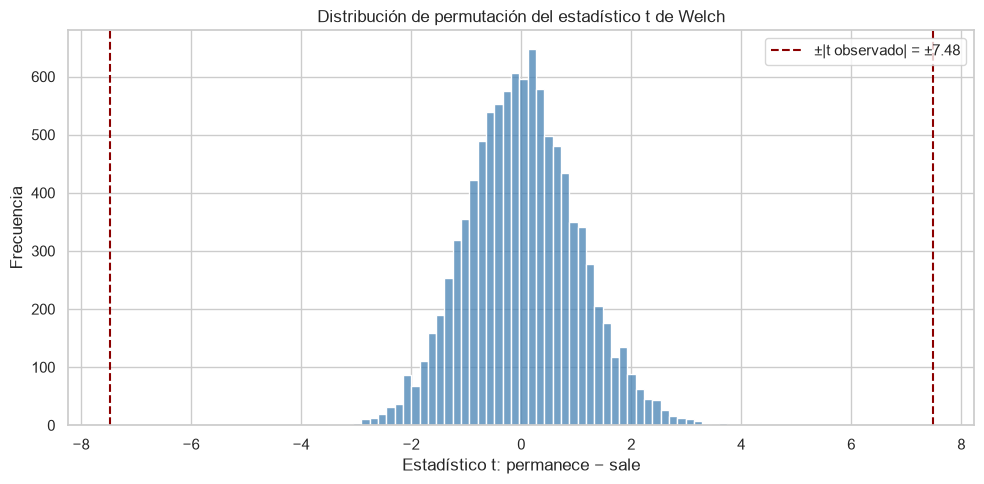

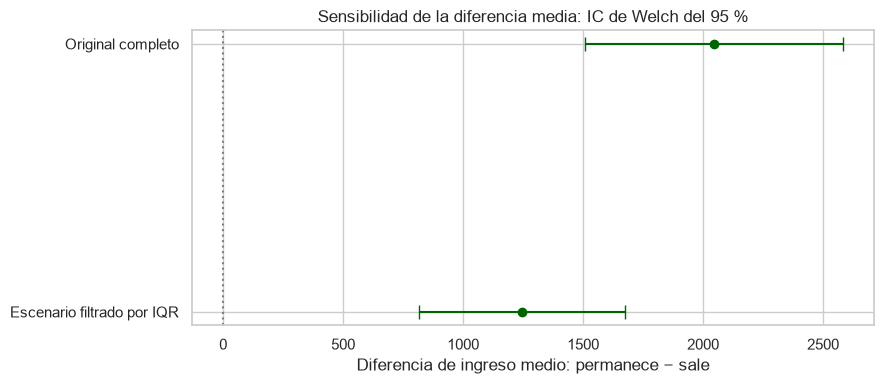

Figuras guardadas en: C:\Users\hernan.saavedra\Documents\2026\Magister\Estadisticas\estadisticaComputacional\S2\figuras
Resultados guardados en: C:\Users\hernan.saavedra\Documents\2026\Magister\Estadisticas\estadisticaComputacional\S2\resultados
Dataset original: sin modificaciones.


In [5]:
# Distribución de permutación: marcar ambas colas del contraste bilateral.
fig, ax = plt.subplots(figsize=(10, 5))

sns.histplot(
    t_permutados,
    bins=50,
    color="steelblue",
    ax=ax
)

ax.axvline(
    abs(t_obs), color="darkred", linestyle="--",
    label=f"±|t observado| = ±{abs(t_obs):.2f}"
)
ax.axvline(
    -abs(t_obs), color="darkred", linestyle="--"
)

ax.set(
    title="Distribución de permutación del estadístico t de Welch",
    xlabel="Estadístico t: permanece − sale",
    ylabel="Frecuencia"
)
ax.legend()
fig.tight_layout()

fig.savefig(
    carpeta_figuras / "rodrigo_permutacion_distribucion.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

# Comparación de diferencias medias e intervalos de Welch.
fig, ax = plt.subplots(figsize=(9, 4))

posiciones = np.arange(len(resumen_sensibilidad))
diferencias = resumen_sensibilidad["diferencia_medias"].to_numpy()

ax.errorbar(
    diferencias,
    posiciones,
    xerr=[
        diferencias - resumen_sensibilidad["ic95_inferior"].to_numpy(),
        resumen_sensibilidad["ic95_superior"].to_numpy() - diferencias
    ],
    fmt="o",
    capsize=5,
    color="darkgreen"
)
ax.axvline(0, color="grey", linestyle=":")
ax.set_yticks(
    posiciones,
    ["Original completo", "Escenario filtrado por IQR"]
)
ax.invert_yaxis()
ax.set(
    title="Sensibilidad de la diferencia media: IC de Welch del 95 %",
    xlabel="Diferencia de ingreso medio: permanece − sale"
)
fig.tight_layout()

fig.savefig(
    carpeta_figuras / "rodrigo_sensibilidad_diferencias.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

# Guardar las permutaciones y su comparación con S1.
pd.DataFrame({
    "permutacion": np.arange(1, N_PERMUTACIONES + 1),
    "t_permutado": t_permutados
}).to_csv(
    carpeta_resultados / "rodrigo_permutacion_replicas.csv",
    index=False,
    encoding="utf-8-sig",
    float_format="%.17g"
)

resumen_permutacion = pd.DataFrame([{
    "comparacion": "permanece - sale",
    "n_permanece": len(ingresos_no),
    "n_sale": len(ingresos_si),
    "t_observado": t_obs,
    "p_welch_s1": referencia_welch["valor_p"],
    "permutaciones": N_PERMUTACIONES,
    "extremos": extremos,
    "p_permutacion": p_permutacion,
    "resolucion_minima_p": 1 / (N_PERMUTACIONES + 1),
    "alfa": ALFA,
    "semilla": SEMILLA,
    "flujo_aleatorio": 5,
    "rechaza_h0": bool(p_permutacion < ALFA)
}])

resumen_permutacion.to_csv(
    carpeta_resultados / "rodrigo_permutacion_resumen.csv",
    index=False,
    encoding="utf-8-sig",
    float_format="%.17g"
)

# Comprobar que el análisis conservó los datos originales.
assert df.equals(original)
assert hashlib.sha256(ruta_datos.read_bytes()).hexdigest() == huella_csv

print("Figuras guardadas en:", carpeta_figuras)
print("Resultados guardados en:", carpeta_resultados)
print("Dataset original: sin modificaciones.")